# 👖 Variational Autoencoders

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow.keras.backend as K
from tensorflow.keras import (layers, models, datasets, callbacks, losses, optimizers, metrics)
from scipy.stats import norm

2026-11-03 12:57:23.288739: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-03 12:57:23.323148: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-03 12:57:25.001243: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 0. Parameters <a name="parameters"></a>

In [2]:
IMAGE_SIZE = 32
BATCH_SIZE = 100
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 2
EPOCHS = 5
BETA = 500

## 1. Prepare the data <a name="prepare"></a>

In [3]:
# Load the data
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()

In [4]:
# Preprocess the data
def preprocess(imgs):

    imgs = imgs.astype("float32") / 255.0
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=0.0)
    imgs = np.expand_dims(imgs, -1)
    
    return imgs

In [5]:
x_train = preprocess(x_train)
x_test = preprocess(x_test)

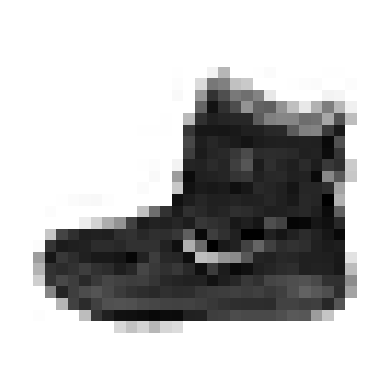

(32, 32, 1)


In [6]:
plt.imshow(x_train[0], cmap="gray_r")
plt.axis("off")
plt.show()
print(x_train[0].shape)

## 2. Build the variational autoencoder <a name="build"></a>

In [18]:
class Sampling(layers.Layer):

    def call(self, inputs):

        z_mean, z_log_var = inputs

        epsilon = tf.random.normal(shape=tf.shape(z_mean))

        return z_mean + tf.exp(0.5 * z_log_var) * epsilon #z = zmean + exp(0.5 × zlog_var) x ϵ

In [19]:
# Encoder
encoder_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 1), name="encoder_input")
x = layers.Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(encoder_input)
x = layers.Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(128, (3, 3), strides=2, activation="relu", padding="same")(x)
shape = x.shape[1:]

x = layers.Flatten()(x)
z_mean = layers.Dense(EMBEDDING_DIM, name="z_mean")(x)
z_log_var = layers.Dense(EMBEDDING_DIM, name="z_log_var")(x)
sampling = Sampling()
z = sampling([z_mean, z_log_var])

encoder = models.Model(encoder_input, [z_mean, z_log_var, z], name="encoder")

In [20]:
# Decoder
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape)))(decoder_input)
x = layers.Reshape(shape)(x)
x = layers.Conv2DTranspose(128, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(32, (3, 3), strides=2, activation="relu", padding="same")(x)
decoder_output = layers.Conv2D(1, (3, 3), strides=1, activation="sigmoid", padding="same", name="decoder_output")(x)

decoder = models.Model(decoder_input, decoder_output)

In [31]:
class VAE(models.Model):

    def __init__(self, encoder, decoder, **kwargs):
        super(VAE, self).__init__(**kwargs)

        self.encoder = encoder
        self.decoder = decoder

        self.total_loss_tracker = metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        
        return [self.total_loss_tracker, self.reconstruction_loss_tracker, self.kl_loss_tracker]

    def call(self, inputs):
        
        z_mean, z_log_var, z = self.encoder(inputs)
        z_s = self.decoder(z)

        return z_mean, z_log_var, z_s

    def train_step(self, data):

        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:

            z_mean, z_log_var, reconstruction = self(data)
            reconstruction_loss = tf.reduce_mean(BETA * losses.binary_crossentropy(data, reconstruction, axis=(1, 2, 3)))
            kl_loss = tf.reduce_mean(tf.reduce_sum(-0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)), axis=1))
            total_loss = reconstruction_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            m.name: m.result()
            for m in self.metrics
        }

    def test_step(self, data):

        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var, reconstruction = self(data)

        reconstruction_loss = tf.reduce_mean(BETA * losses.binary_crossentropy(data, reconstruction, axis=(1, 2, 3)))

        kl_loss = tf.reduce_mean(tf.reduce_sum(-0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)), axis=1))

        total_loss = reconstruction_loss + kl_loss

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }
        

    def get_config(self):

        config = super().get_config()
    
        config.update({
            "encoder": tf.keras.utils.serialize_keras_object(self.encoder),
            "decoder": tf.keras.utils.serialize_keras_object(self.decoder)
        })
    
        return config

        
    @classmethod
    def from_config(cls, config):
        
        encoder = tf.keras.utils.deserialize_keras_object(config.pop("encoder"))
        decoder = tf.keras.utils.deserialize_keras_object(config.pop("decoder"))
    
        return cls(encoder=encoder, decoder=decoder, **config)

In [32]:
vae = VAE(encoder, decoder)

## 3. Train the variational autoencoder <a name="train"></a>

In [33]:
optimizer = optimizers.Adam(learning_rate=0.0005)
vae.compile(optimizer=optimizer)

In [34]:
callback = callbacks.ModelCheckpoint(filepath="vae.keras", save_weights_only=False, save_freq="epoch", monitor="loss", mode="min", save_best_only=True, verbose=1)

In [35]:
vae.fit(x_train, epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, validation_data=(x_test, x_test), callbacks=callback)

Epoch 1/5
590/600 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 5.0409 - reconstruction_loss: 129.9586 - total_loss: 134.9995
Epoch 1: finished saving model to vae.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - kl_loss: 5.0682 - reconstruction_loss: 129.2297 - total_loss: 134.2979 - val_kl_loss: 5.1160 - val_loss: 137.6295 - val_reconstruction_loss: 132.5135
Epoch 2/5
597/600 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 5.1127 - reconstruction_loss: 128.2847 - total_loss: 133.3974
Epoch 2: finished saving model to vae.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - kl_loss: 5.1197 - reconstruction_loss: 128.1882 - total_loss: 133.3079 - val_kl_loss: 5.1599 - val_loss: 137.0981 - val_reconstruction_loss: 131.9382
Epoch 3/5
599/600 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 5.1424 - reconstruction_loss: 127.5290 - total_loss: 132.6714
Epoch 3: finished saving model to vae.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - kl_loss: 5.1509 - reconstruction_loss: 127.4928 - total_loss: 132.

In [36]:
encoder.save("vae.encoder.keras")
decoder.save("vae.decoder.keras")

## 3. Reconstruct using the variational autoencoder <a name="reconstruct"></a>

In [38]:
# Select a subset of the test set
n_to_predict = 5000
example_images = x_test[:n_to_predict]
example_labels = y_test[:n_to_predict]

In [40]:
# Create autoencoder predictions and display
z_mean, z_log_var, reconstructions = vae.predict(example_images)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


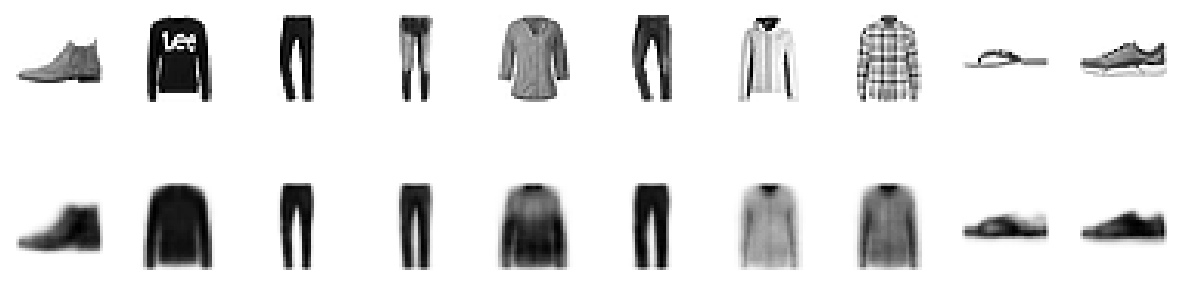

In [41]:
plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(example_images[i], cmap="gray_r")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructions[i], cmap="gray_r")
    plt.axis("off")

plt.show()

## 4. Embed using the encoder <a name="encode"></a>

In [42]:
z_mean, z_var, z = encoder.predict(example_images)

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [43]:
# Some examples of the embeddings
print(z[:10])

[[-0.5091156   1.3980142 ]
 [-0.6882765  -0.19982584]
 [-0.04768897 -2.5677965 ]
 [ 1.3279601  -2.1750956 ]
 [ 0.19002345 -0.06623948]
 [-0.04029176 -1.7798667 ]
 [ 1.2417896  -0.17211144]
 [ 0.607779   -0.1886176 ]
 [ 2.4702582   1.8019959 ]
 [ 1.1717298   1.4155301 ]]


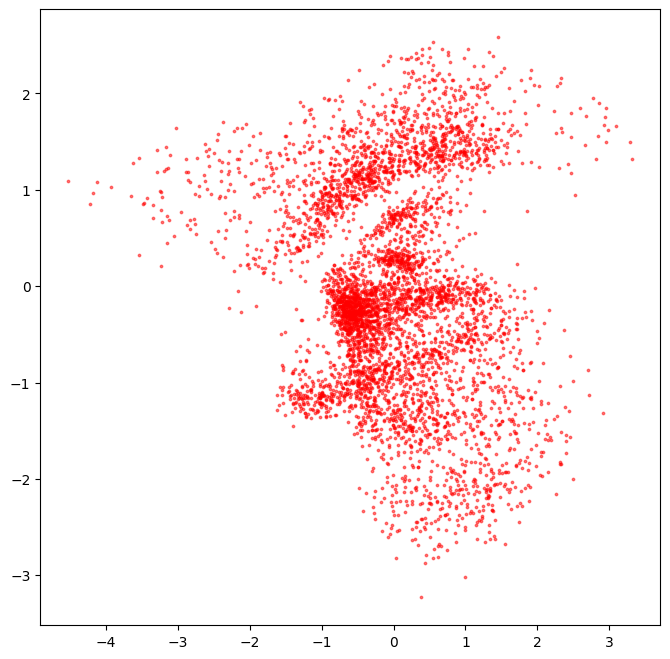

In [79]:
# Show the encoded points in 2D space
plt.figure(figsize=(8, 8))
plt.scatter(z.T[0], z.T[1], c="r", alpha=0.5, s=3)
plt.show()

## 5. Generate using the decoder <a name="decode"></a>

In [81]:
# Sample some points in the latent space, from the standard normal distribution
grid_width, grid_height = (6, 3)
z_sample = np.random.normal(size=(grid_width * grid_height, 2))

In [82]:
# Decode the sampled points
reconstructions = decoder.predict(z_sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


In [83]:
# Convert original embeddings and sampled embeddings to p-values
p = norm.cdf(z)
p_sample = norm.cdf(z_sample)

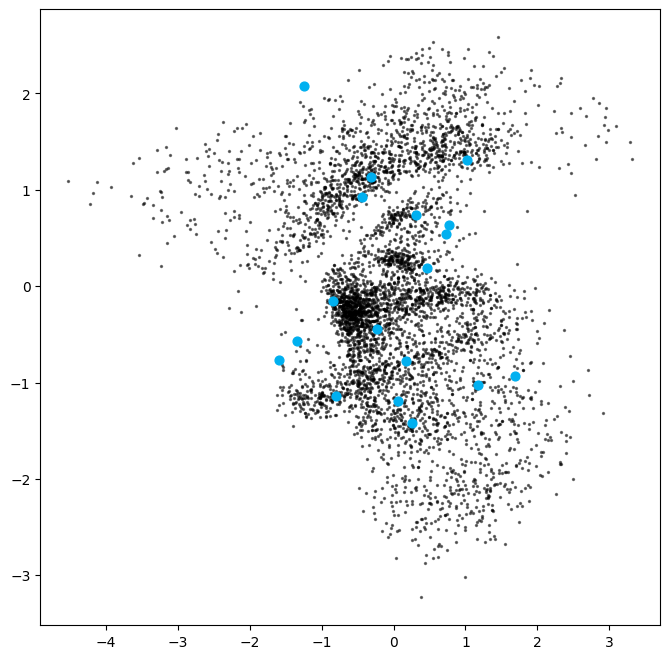

In [84]:
figsize = 8
plt.figure(figsize=(figsize, figsize))
plt.scatter(z.T[0], z.T[1], c="black", alpha=0.5, s=2)
plt.scatter(z_sample.T[0], z_sample.T[1], c="#00B0F0", s=40)
plt.show()

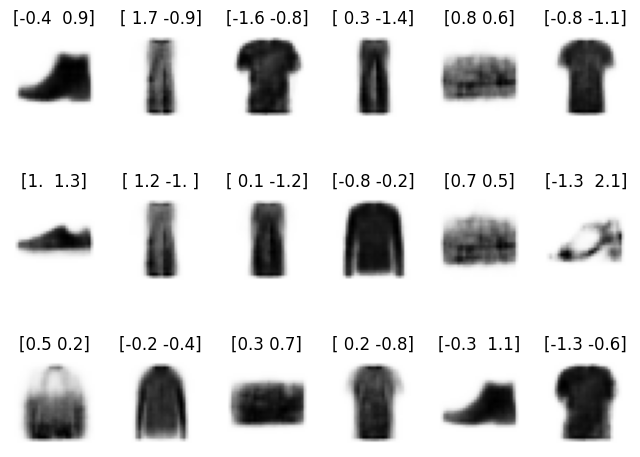

In [89]:
# Display reconstructed images
fig = plt.figure(figsize=(figsize, grid_height * 2))

for i in range(grid_width * grid_height):
    
    ax = fig.add_subplot(grid_height, grid_width, i + 1)
    ax.imshow(reconstructions[i, :, :], cmap="Greys")
    ax.axis("off")
    ax.set_title(str(np.round(z_sample[i, :], 1)))

plt.show()

## 6. Explore the latent space <a name="explore"></a>

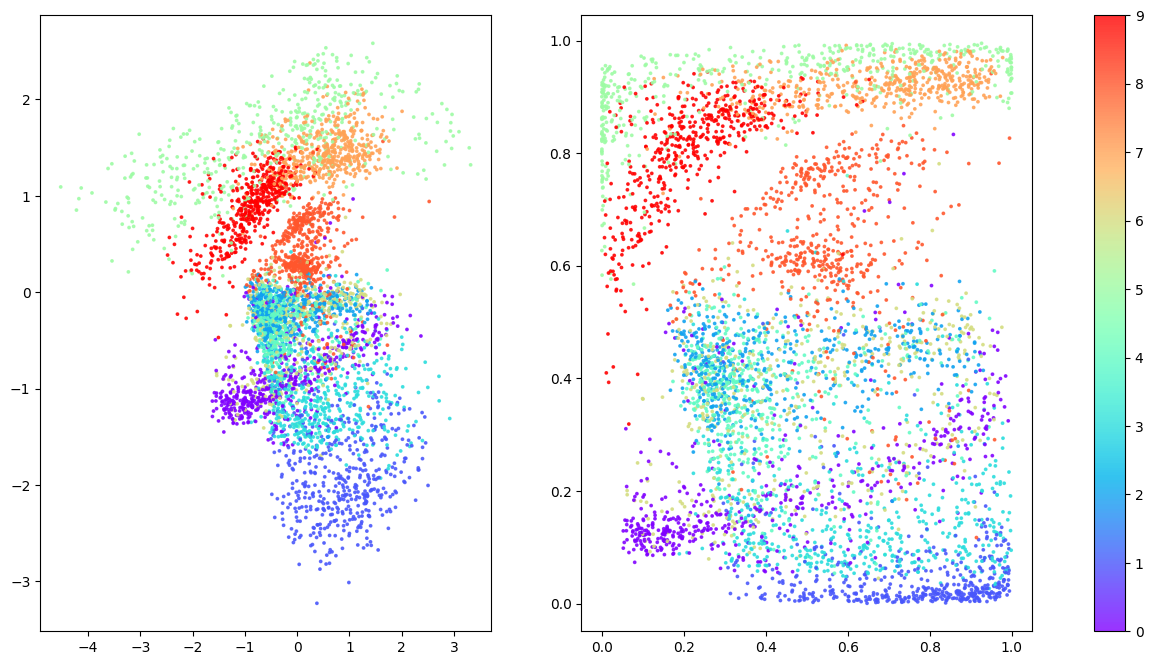

In [70]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].scatter(z.T[0], z.T[1], c=example_labels, cmap="rainbow", s=3, alpha=0.8)
ax[1].scatter(p.T[0], p.T[1], c=example_labels, cmap="rainbow", s=3, alpha=0.8)
plt.colorbar(ax[0].collections[0], ax=ax)
plt.show()

| ID | Clothing Label |
| :- | :- |
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

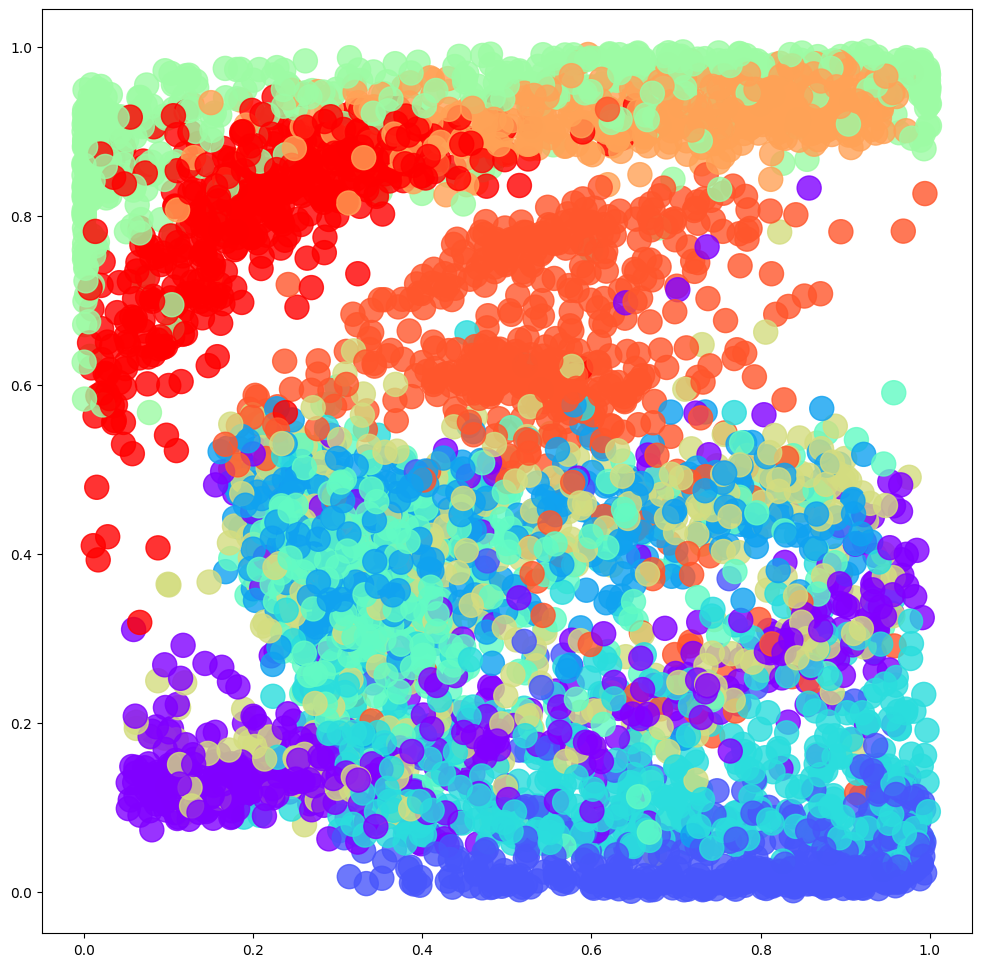

In [90]:
figsize = 12
grid_size = 15

# Plot latent space
plt.figure(figsize=(figsize, figsize))
plt.scatter(p.T[0], p.T[1], c=example_labels, cmap="rainbow", s=300, alpha=0.8)
plt.show()

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


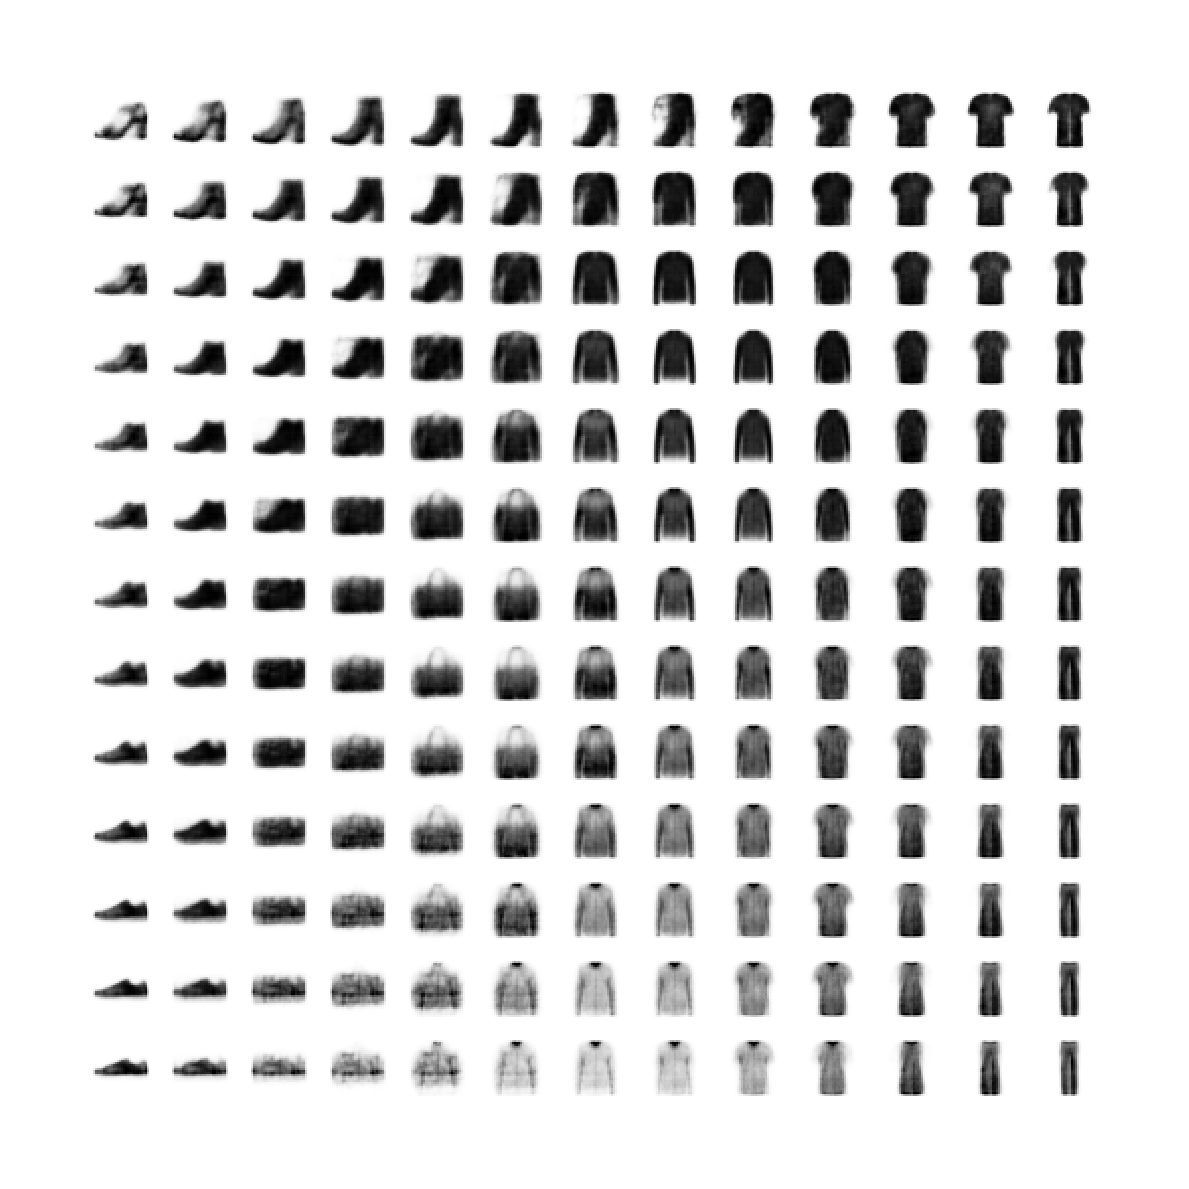

In [73]:
# Generate a 2D grid of latent points
x = norm.ppf(np.linspace(0, 1, grid_size))
y = norm.ppf(np.linspace(1, 0, grid_size))

grid = np.array(np.meshgrid(x, y)).T.reshape(-1, 2)

# Generate images from latent points
reconstructions = decoder.predict(grid)

# Display generated images
fig, ax = plt.subplots(grid_size, grid_size, figsize=(figsize, figsize))

for i in range(grid_size):
    for j in range(grid_size):
        ax[i, j].imshow(
            reconstructions[i * grid_size + j],
            cmap="Greys"
        )
        ax[i, j].axis("off")

plt.tight_layout()
plt.show()